# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

In [28]:
# Preliminares
import pandas as pd

from src.modeling import (
    cargar_datos_clean, filtrar_pares_restantes, separar_datos_live,
    categorizar_en_cuantiles
    )
from src.transform import encontrar_columnas
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    top_correlaciones, pintar_violin_plots 
)

# Cargar fichero de precios
df_clean = cargar_datos_clean()

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 967 entries, 2007-04-30 to 2026-11-02
Data columns (total 83 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   EURUSD_intra_weekly               967 non-null    float64
 1   GBPUSD_intra_weekly               967 non-null    float64
 2   USDJPY_intra_weekly               967 non-null    float64
 3   USDCAD_intra_weekly               967 non-null    float64
 4   USDCHF_intra_weekly               967 non-null    float64
 5   AUDUSD_intra_weekly               967 non-null    float64
 6   EURUSD_return_zscore_lag1         967 non-null    float64
 7   EURUSD_acceleration_zscore_lag1   967 non-null    float64
 8   EURUSD_ret_diff_zscore_lag1       967 non-null    float64
 9   EURUSD_accel_diff_zscore_lag1     967 non-null    float64
 10  EURUSD_vol_ratio_lag1             967 non-null    float64
 11  EURUSD_range10_position_lag1      967 non-null    fl

## Analisis de variables

In [29]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

In [30]:
# Descripcion de variables
columnas_clean = df_clean.columns.tolist()
cadena = "_vol_ratio_"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)

df_clean[columnas].describe().T

,count,mean,std,min,25%,50%,75%,max
EURUSD_vol_ratio_lag1,967.0,1.298424,0.474674,0.787797,0.970810,1.138817,1.476195,3.722388
GBPUSD_vol_ratio_lag1,967.0,1.320203,0.470404,0.789222,0.983601,1.168314,1.508794,3.962856
USDJPY_vol_ratio_lag1,967.0,1.358318,0.573395,0.783400,0.975414,1.175772,1.543478,4.430857
USDCHF_vol_ratio_lag1,967.0,1.298492,0.456415,0.776071,0.982330,1.164925,1.498247,5.991191
AUDUSD_vol_ratio_lag1,967.0,1.310916,0.457543,0.782398,0.980216,1.164388,1.501607,3.755842
USDCAD_vol_ratio_lag1_log,967.0,0.219887,0.344357,-0.265615,-0.024085,0.152346,0.389172,1.906788


In [31]:
# Asimetrias general
mostrar_asimetrias(df_clean)

Gold_Volume_zscore_lag1             2.968310
SPY_Volume_zscore_lag1              2.640010
USDCHF_vol_ratio_lag1               2.385081
VIX_level                           2.358869
USDCAD_accel_diff_zscore_lag1       2.129886
USDJPY_vol_ratio_lag1               2.012608
USDCAD_variance_lag1_log            2.010929
EURUSD_vol_ratio_lag1               1.737247
AUDUSD_vol_ratio_lag1               1.658784
GBPUSD_vol_ratio_lag1               1.645145
USDCAD_vol_ratio_lag1_log           1.370659
USDJPY_open_gap_zscore_lag1_yeo     1.227657
USDCHF_variance_lag1_log            1.077862
USDCHF_accel_diff_zscore_lag1       1.044605
USDCHF_open_gap_zscore_lag1_yeo     1.032825
Oil_variance_lag1_log               0.789492
SPY_acceleration_zscore_lag1        0.669365
GBPUSD_variance_lag1_log            0.617579
Oil_return_zscore_lag1              0.575663
AUDUSD_sma15_pct_diff_sma50_lag1    0.562723
USDJPY_sma15_pct_diff_sma50_lag1    0.529410
Oil_acceleration_zscore_lag1        0.419187
USDCAD_ret

In [32]:
# Asimetria por grupo
cadena = "_open_gap_"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)
mostrar_asimetrias(df_clean[columnas])

USDJPY_open_gap_zscore_lag1_yeo    1.227657
USDCHF_open_gap_zscore_lag1_yeo    1.032825
EURUSD_open_gap_zscore_lag1_yeo    0.403194
GBPUSD_open_gap_zscore_lag1_yeo   -0.061283
AUDUSD_open_gap_zscore_lag1_yeo   -0.256008
USDCAD_open_gap_zscore_lag1_yeo   -3.727548


Cont


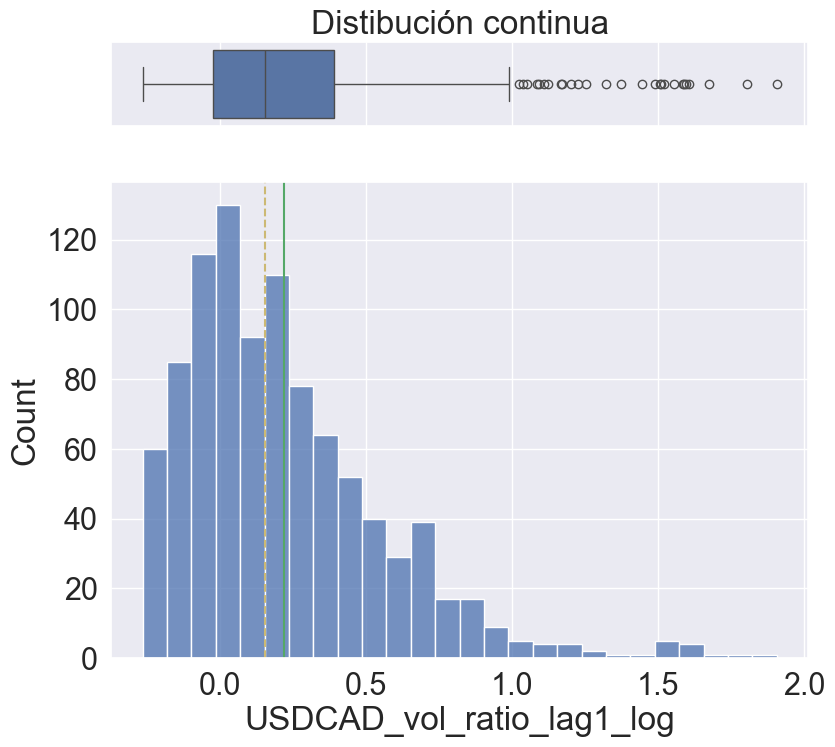

In [34]:
# Visualizar columna
col = 'USDCAD_vol_ratio_lag1_log'
pintar_columna(df_clean[col])

In [35]:
# Tabla de Correlaciones
top_correlaciones(df=df_clean, top_n=30)

,Variable A,Variable B,correlation
1067,AUDUSD_sma15_pct_diff_sma50_lag1,USDCAD_sma15_pct_diff_sma50_lag1,0.833161
753,USDCHF_sma15_pct_diff_sma50_lag1,EURUSD_sma15_pct_diff_sma50_lag1,0.785197
405,USDCAD_acceleration_zscore_lag1,USDCAD_return_zscore_lag1,0.753390
2012,USDCHF_variance_lag1_log,EURUSD_variance_lag1_log,0.750390
714,USDCHF_range10_position_lag1,EURUSD_range10_position_lag1,0.745823
594,USDCHF_acceleration_zscore_lag1,USDCHF_return_zscore_lag1,0.736460
603,USDCHF_ret_diff_zscore_lag1,EURUSD_ret_diff_zscore_lag1,0.725646
1377,SPY_acceleration_zscore_lag1,SPY_return_zscore_lag1,0.723079
230,USDJPY_acceleration_zscore_lag1,USDJPY_return_zscore_lag1,0.720036
860,AUDUSD_acceleration_zscore_lag1,AUDUSD_return_zscore_lag1,0.715651


## Analisis de labels

In [36]:
simbolo_objetivo = 'EURUSD'
# Cargar fichero de precios
df = cargar_datos_clean()
df = filtrar_pares_restantes(df,simbolo_objetivo)

# Separar datos de entrenamiento y test  
ultima_fecha = df.index.max()
df_train, df_live = separar_datos_live(df=df, fecha=ultima_fecha)

# Se crea la variable categorica a partir del dataset de entrenamiento
# Variable objetivo: se crea variable categorica por cuantiles
objetivo = f"{simbolo_objetivo}_intra_weekly"
objetivo_cat = f"{objetivo}_cat"

df_train, tabla_bins = categorizar_en_cuantiles(
    df_train, 
    columna=objetivo, 
    num_cuantiles=3, 
    quitar_original=True
    )


print(f"\n--- Rangos por Categoría para el ticker {simbolo_objetivo} ---")
print(tabla_bins)


--- Rangos por Categoría para el ticker EURUSD ---
   categoria  lim_inferior  lim_superior
0          1     -0.039486     -0.003876
1          2     -0.003876      0.005203
2          3      0.005203      0.045143


In [37]:
df_train[objetivo_cat].value_counts()

EURUSD_intra_weekly_cat
1    322
2    322
3    322
Name: count, dtype: int64

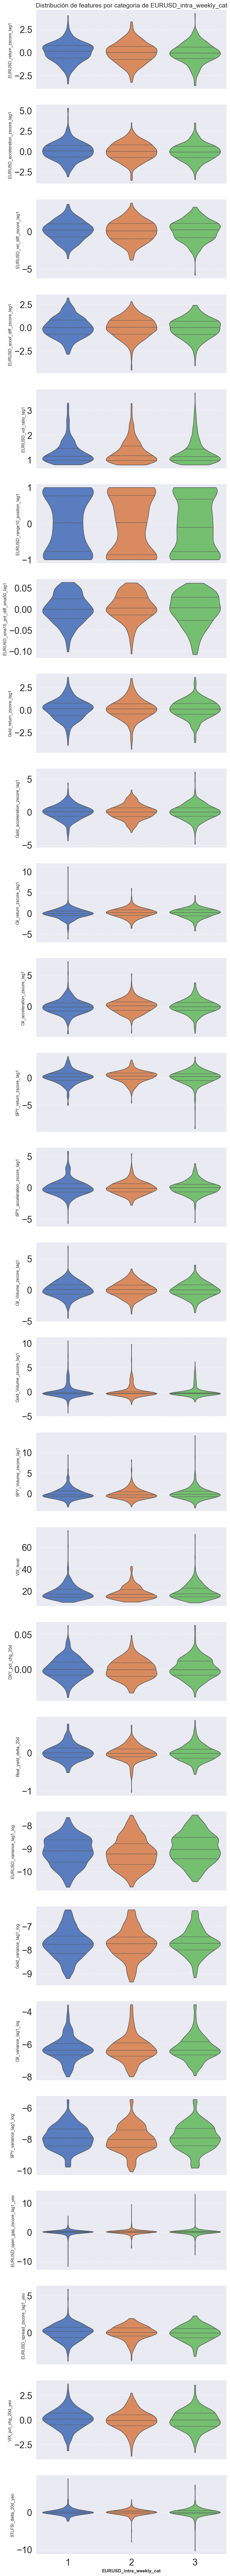

In [38]:
# Violin plot
# Identificar las variables numéricas excluyendo la variable objetivo
target_col = objetivo_cat
numeric_cols = df_train.select_dtypes(include=["number"]).columns.tolist()

# Asegurar que la columna objetivo no esté en la lista
numeric_cols = [col for col in numeric_cols if col != target_col]

# Filtrar por grupo de variables
#cadena = "EURUSD"
#columnas = encontrar_columnas(columnas_target=numeric_cols, cadena=cadena)

pintar_violin_plots(
    df=df_train,
    numeric_cols=numeric_cols,
    target_col=target_col
)